<a href="https://colab.research.google.com/github/stefisha/genai24/blob/main/grounding_dino_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Intitial setup

In [ ]:
import os
HOME = os.getcwd()
print(HOME)
%cd {HOME}
!git clone https://github.com/IDEA-Research/GroundingDINO.git
%cd {HOME}/GroundingDINO
!pip install datumaro
!pip install -r requirements.txt
!pip install -q -e .

/content
/content
Cloning into 'GroundingDINO'...
remote: Enumerating objects: 463, done.
remote: Counting objects: 100% (240/240), done.
remote: Compressing objects: 100% (105/105), done.
remote: Total 463 (delta 175), reused 135 (delta 135), pack-reused 223 (from 1)
Receiving objects: 100% (463/463), 12.87 MiB | 17.96 MiB/s, done.
Resolving deltas: 100% (241/241), done.
/content/GroundingDINO
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.4/50.4 kB 3.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 60.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.9/141.9 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 705.5/705.5 kB 55.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.6/42.6 MB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.8/117.8 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

Verify that configuration is correct

In [ ]:
import os

CONFIG_PATH = os.path.join(HOME, "GroundingDINO/groundingdino/config/GroundingDINO_SwinT_OGC.py")
print(CONFIG_PATH, "; exist:", os.path.isfile(CONFIG_PATH))

/content/GroundingDINO/groundingdino/config/GroundingDINO_SwinT_OGC.py ; exist: True


## Download Grounding DINO weights

In [ ]:
%cd {HOME}
!mkdir {HOME}/weights
%cd {HOME}/weights

!wget -q https://github.com/IDEA-Research/GroundingDINO/releases/download/v0.1.0-alpha/groundingdino_swint_ogc.pth

/content
/content/weights


In [ ]:
import os

WEIGHTS_NAME = "groundingdino_swint_ogc.pth"
WEIGHTS_PATH = os.path.join(HOME, "weights", WEIGHTS_NAME)
print(WEIGHTS_PATH, "; exist:", os.path.isfile(WEIGHTS_PATH))

/content/weights/groundingdino_swint_ogc.pth ; exist: True


##Download image to be annotated

In [8]:
%cd {HOME}
!mkdir {HOME}/data
%cd {HOME}/data

#!wget -q https://media.istockphoto.com/id/1319636830/vector/set-of-wooden-chairs-for-outdoor-and-indoor-usage-retro-chair-without-cushion-flat-vector.jpg?s=612x612&w=0&k=20&c=mQeYCC0ryra8IdCVmYHnxSiZUpP8NdQF5OKandWtrI4=

/content
mkdir: cannot create directory ‘/content/data’: File exists
/content/data


##Load Grounding DINO model

In [ ]:
%cd {HOME}/GroundingDINO

from groundingdino.util.inference import load_model, load_image, predict, annotate

model = load_model(CONFIG_PATH, WEIGHTS_PATH)

/content/GroundingDINO


final text_encoder_type: bert-base-uncased


The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

##Using the model

We will first perform inference on the downloaded images, then save the annotations to be exported in COCO format. Tweak the text prompts to get to your desired output.

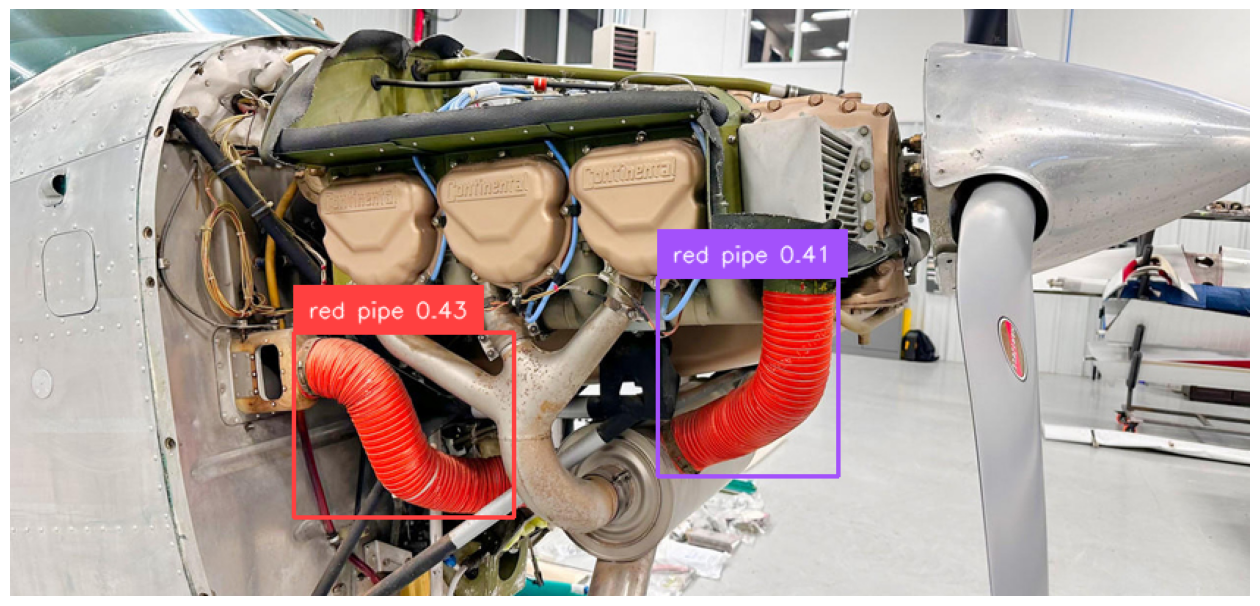

AssertionError: Directly initalizing Image is not supported. Please use one of fractory functions (Image.from_file(), Image.from_numpy(), Image.from_bytes()).

In [16]:
import os
import supervision as sv
import torch
from datumaro import Polygon, Bbox, RleMask, Dataset, DatasetItem, Image


images = ["cessna-185-engine-parts.jpg"]
results = []
for image_name in images:
  image_path = os.path.join(HOME, "data", image_name)

  TEXT_PROMPT = "red pipe"
  BOX_TRESHOLD = 0.35
  TEXT_TRESHOLD = 0.25

  image_source, image = load_image(image_path)
  # Generate predictions
  boxes, logits, phrases = predict(
      model=model,
      image=image,
      caption=TEXT_PROMPT,
      box_threshold=BOX_TRESHOLD,
      text_threshold=TEXT_TRESHOLD
  )

  annotated_frame = annotate(image_source=image_source, boxes=boxes, logits=logits, phrases=phrases)

  %matplotlib inline
  sv.plot_image(annotated_frame, (16, 16))


  h, w, _ = image_source.shape
  # Assemble annotations to be used by datumaro
  annotations = []
  for box in boxes:
    result = box * torch.Tensor([w, h, w, h])
    annotations.append(Bbox(result[0], result[1], result[2], result[3], label=1))

  results.append(
      DatasetItem(
        id=image_name.split(".")[0],
        media=Image(path=image_path),
        annotations=annotations
        )
      )
dataset = Dataset.from_iterable(results,categories = [TEXT_PROMPT])


Export from datumaro

In [ ]:
dataset.export("./coco_export.json",format="coco")

You may now download the exported COCO file for training, or run a validation workflow to refine the accuracy of the annotations.

In [15]:
while True:
    pass

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "<ipython-input-15-b7133701d76c>", line 1, in <cell line: 1>
    while True:
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/IPython/core/interactiveshell.py", line 2099, in showtraceback
    stb = value._render_traceback_()
AttributeError: 'KeyboardInterrupt' object has no attribute '_render_traceback_'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/IPython/core/ultratb.py", line 1101, in get_records
    return _fixed_getinnerframes(etb, number_of_lines_of_context, tb_offset)
  File "/usr/local/lib/python3.10/dist-packages/IPython/core/ultratb.py", line 248, in 

TypeError: object of type 'NoneType' has no len()